In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score 
from sklearn.pipeline import Pipeline                                                  
from sklearn.tree import DecisionTreeRegressor                         
from sklearn.compose import ColumnTransformer                               
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.impute import SimpleImputer
from lightgbm import LGBMRegressor
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import math
from sklearn.compose import TransformedTargetRegressor

In [44]:
df=pd.read_csv("MachineLearningDataSets/21-housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [45]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [47]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [48]:
df[df["total_bedrooms"].isnull()]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


In [49]:
df[df.duplicated()] # there is no duplicated value

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity


# Train - Test

In [51]:
X=df.drop(columns="median_house_value",axis=1)
y=df["median_house_value"]

In [52]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [53]:
# detect outlier values

In [54]:
def get_iqr_bounds(series,k=3.0):
    Q1=series.quantile(0.25)
    Q3=series.quantile(0.75)
    iqr=Q3-Q1
    lower=Q1 - k*iqr
    upper=Q3 + k*iqr
    return lower,upper

In [55]:
outlier_columns=["total_rooms","total_bedrooms","population","households"]
bounds={}

In [56]:
for col in outlier_columns:
    lower,upper=get_iqr_bounds(X_train[col],k=3.0)
    bounds[col]=(lower,upper)
    print(f"{col} alt sınırı : {lower} , üst siniri {upper}")

total_rooms alt sınırı : -3680.75 , üst siniri 8306.75
total_bedrooms alt sınırı : -760.0 , üst siniri 1704.0
population alt sınırı : -2017.0 , üst siniri 4535.0
households alt sınırı : -701.0 , üst siniri 1588.0


In [57]:
def clip_outliers(df,bounds):
    df=df.copy()                                                      
    for col,(lower,upper) in bounds.items():
        df[col]=df[col].clip(lower=lower,upper=upper)
    return df

In [58]:
X_train=clip_outliers(X_train,bounds)                               
X_test=clip_outliers(X_test,bounds)

In [59]:
# new feautures

In [60]:
def add_engineered_feautures(X):
    X=X.copy()
    X["rooms_per_household"] = X["total_rooms"] / X["households"]
    X["bedrooms_per_room"] = X["total_bedrooms"] / X["total_rooms"]
    X["population_per_household"] = X["population"] / X["households"]
    return X

In [61]:
X_train=add_engineered_feautures(X_train)
X_test=add_engineered_feautures(X_test)

In [62]:
# high outlier values

In [63]:
num_cols_raw=X_train.select_dtypes(include=np.number).columns

In [64]:
num_cols_raw

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_per_room', 'population_per_household'],
      dtype='object')

In [65]:
feature_corr=X_train[num_cols_raw].corr()

In [66]:
threshold=0.9
high_corr_pairs=[]
for i in range(len(feature_corr.columns)):
    for j in range(i+1,len(feature_corr.columns)):
        col_i=feature_corr.columns[i]
        col_j=feature_corr.columns[j]
        corr_val=feature_corr.iloc[i,j]
        if abs(corr_val)>threshold:
            high_corr_pairs.append((col_i,col_j,corr_val))
    

In [67]:
print(f"Corr {threshold}'dan büyük olan çiftler")
for col_i,col_j,corr_val in high_corr_pairs:
    print(f"{col_i} <-> {col_j} : {corr_val}")

Corr 0.9'dan büyük olan çiftler
longitude <-> latitude : -0.923408319676947
total_rooms <-> total_bedrooms : 0.9224548415447777
total_rooms <-> households : 0.9137937148447188
total_bedrooms <-> households : 0.9792321627136104
population <-> households : 0.9076064421319613


In [68]:
columns_to_drop=list(set(col_j for _,col_j,_ in high_corr_pairs))
columns_to_drop.remove("latitude")
print(columns_to_drop)

['total_bedrooms', 'households']


In [69]:
X_train=X_train.drop(columns=columns_to_drop)
X_test=X_test.drop(columns=columns_to_drop)

# Data Preprocessing Pipeline

In [71]:
cat_cols=["ocean_proximity"]
num_cols=X_train.select_dtypes(include=np.number).columns

In [73]:
num_pipeline=Pipeline([
    ("Imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler()),
])

In [74]:
cat_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore")),
])

In [75]:
preprocessor=ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat",cat_pipeline,cat_cols)
])

In [76]:
# machine learning with XGBRegressor

In [77]:
full_pipeline=Pipeline([
    ("preprocessing",preprocessor),
    ("model",XGBRegressor(
        n_estimators=200,
        max_depth=4,          # varsayılan genelde 6, düşürmek overfit'i azaltır
        learning_rate=0.05,   # düşük learning rate + yeterli n_estimators
        subsample=0.8,        # her ağaçta verinin %80'ini kullan
        colsample_bytree=0.8, # her ağaçta feature'ların %80'ini kullan
        reg_alpha=1,          # L1 regularization
        reg_lambda=1,         # L2 regularization
        random_state=42,
    )),
])

In [78]:
full_pipeline.fit(X_train,y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [79]:
y_pred=full_pipeline.predict(X_test)

In [80]:
def evaluate_model(y_test,y_pred):
    mae=mean_absolute_error(y_test,y_pred)
    mse=mean_squared_error(y_test,y_pred)
    r_score=r2_score(y_test,y_pred)
    return mae,mse,r_score

In [81]:
mae,mse,r_score=evaluate_model(y_test,y_pred)

In [82]:
print(f"r_score:{r_score}")

r_score:0.8120253445498797


# Trying different machine learning models

In [ ]:
# models
models ={
    "Linear Regression" : LinearRegression(),
    "Lasso" : Lasso(),
    "Ridge" : Ridge(),
    "K Neighbors Regressor" : KNeighborsRegressor(),
    "Decision Tree" : DecisionTreeRegressor(),
    "Random Forest Regressor" : RandomForestRegressor(),
    "Adaboost Regressor" : AdaBoostRegressor(),
    "Gradient Boost Regressor" : GradientBoostingRegressor(),
    "XGBoost Regressor" : XGBRegressor()
}

In [ ]:
def calculate(models):
    for model_name,model_ in models.items():
        model=model_
        model_pipe=Pipeline([
            ("Preprocessing",preprocessor),
            ("model",model),
        ])
        model_pipe.fit(X_train,y_train)
        y_pred_train=model_pipe.predict(X_train)
        y_pred_test=model_pipe.predict(X_test)
        
        train_mae,train_mse,train_r_score=evaluate_model(y_train,y_pred_train)
        test_mae,test_mse,test_r_score=evaluate_model(y_test,y_pred_test)
        
        print(f"Model performance for training")
        print(f"Model name :{model_name}")
        print(f"Model mae :{train_mae}")
        print(f"Model mse :{train_mse}")
        print(f"Model r score :{train_r_score}")

        print("----")
        
        print(f"Model performance for test")
        print(f"Model name :{model_name}")
        print(f"Model mae :{test_mae}")
        print(f"Model mse :{test_mse}")
        print(f"Model r score :{test_r_score}")
        print("----------------")



In [ ]:
#calculate(models)

In [84]:
# randomized search -Hyperparameter tuning

In [85]:
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)
full_pipe_random=Pipeline([
    ("Preprocessing",preprocessor),
    ("model",xgb_model),   
    ])
params = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.03, 0.05],
    "model__max_depth": [2, 3, 4],
    "model__min_child_weight": [5, 7, 10],
    "model__subsample": [0.6, 0.7, 0.8],
    "model__colsample_bytree": [0.6, 0.7, 0.8],
    "model__gamma": [0.1, 0.3, 0.5],
    "model__reg_alpha": [0.1, 1, 5],
    "model__reg_lambda": [1, 2, 5, 10],
}

In [86]:
random=RandomizedSearchCV(
    estimator=full_pipe_random,
    param_distributions=params,
    n_jobs=-1,
    verbose=2,
    n_iter=40,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
)

In [87]:
random.fit(X_train,y_train)

y_pred_train=random.predict(X_train)
y_pred_test=random.predict(X_test)
        
train_mae,train_mse,train_r_score=evaluate_model(y_train,y_pred_train)
test_mae,test_mse,test_r_score=evaluate_model(y_test,y_pred_test)
        
print(f"Model performance for training")
print(f"Model mae :{train_mae}")
print(f"Model mse :{train_mse}")
print(f"Model r score :{train_r_score}")

print(f"Model performance for test")
print(f"Model mae :{test_mae}")
print(f"Model mse :{test_mse}")
print(f"Model r score :{test_r_score}")

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Model performance for training
Model mae :32207.509772519337
Model mse :2194195106.1454906
Model r score :0.8362169370482057
Model performance for test
Model mae :34124.14385245074
Model mse :2519326211.443777
Model r score :0.8080572017231603


# cross validation

In [89]:
cross_score=cross_val_score(
    estimator=random.best_estimator_,
    X=X_train,y=y_train,
    scoring="neg_root_mean_squared_error",
    cv=5,
)

In [90]:
print(cross_score.mean())

-50671.791443492824


# LGBMregressor

In [94]:
light=LGBMRegressor(random_state=42,n_jobs=-1)

In [95]:
full_pipeline_light=Pipeline([
    ("Preprocessing",preprocessor),
    ("model",light),   
    ])

In [96]:
full_pipeline_light.fit(X_train,y_train)
y_pred_train=full_pipeline_light.predict(X_train)
y_pred_test=full_pipeline_light.predict(X_test)
        
train_mae,train_mse,train_r_score=evaluate_model(y_train,y_pred_train)
test_mae,test_mse,test_r_score=evaluate_model(y_test,y_pred_test)
        
print(f"Model performance for training")
print(f"Model mae :{train_mae}")
print(f"Model mse :{train_mse}")
print(f"Model r score :{train_r_score}")

print(f"Model performance for test")
print(f"Model mae :{test_mae}")
print(f"Model mse :{test_mse}")
print(f"Model r score :{test_r_score}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000756 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2101
[LightGBM] [Info] Number of data points in the train set: 14448, number of used features: 13
[LightGBM] [Info] Start training from score 206923.960894
Model performance for training
Model mae :26691.12280591041
Model mse :1508416682.351084
Model r score :0.8874060452732306
Model performance for test
Model mae :30617.41326553038
Model mse :2087450076.717622
Model r score :0.8409610445966157


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


# Model training with TransformedTargetRegressor and LGMBregressor

In [127]:
num_pipeline=Pipeline([
    ("Imputer",SimpleImputer(strategy="median")),
    ("power_transformer", PowerTransformer(method="yeo-johnson",standardize=False)),
    ("scaler",StandardScaler()),
])
cat_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore")),
])
preprocessor=ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat",cat_pipeline,cat_cols)
])
model_with_target_transform=TransformedTargetRegressor(
    regressor=light,
    transformer=PowerTransformer(method="yeo-johnson")
)
full_pipeline_light_target=Pipeline([
    ("Preprocessing",preprocessor),
    ("model",model_with_target_transform)
])

In [128]:
full_pipeline_light_target.fit(X_train,y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000613 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2101
[LightGBM] [Info] Number of data points in the train set: 14448, number of used features: 13
[LightGBM] [Info] Start training from score 0.000000


,steps,"[('Preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [129]:
y_pred=full_pipeline_light_target.predict(X_test)

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [130]:
print(r2_score(y_test,y_pred))

0.8309007363810925


In [131]:
#lets get X_train_transformed_df

In [134]:
X_train_transformed=full_pipeline_light_target.named_steps["Preprocessing"].transform(X_train)

In [109]:
feature_names=preprocessor.get_feature_names_out()

In [135]:
X_train_transformed_df=pd.DataFrame(data=X_train_transformed,columns=feature_names)
#X_train_transformed_df.head()

In [136]:
def all_graphics(df,title_prefix):
    numeric_columns=df.select_dtypes(include=np.number).columns
    n_columns=3
    n_rows=math.ceil(len(numeric_columns)/3)

    plt.figure(figsize=(n_columns*9,n_rows*5))
    for i,col in enumerate(numeric_columns):
        plt.subplot(n_rows,n_columns,i+1)
        sns.histplot(data=df,x=col,bins=50,kde=True)
        plt.title(f"{title_prefix}{col}")
        plt.xlabel("")
        plt.ylabel("")
plt.tight_layout()    


<Figure size 640x480 with 0 Axes>

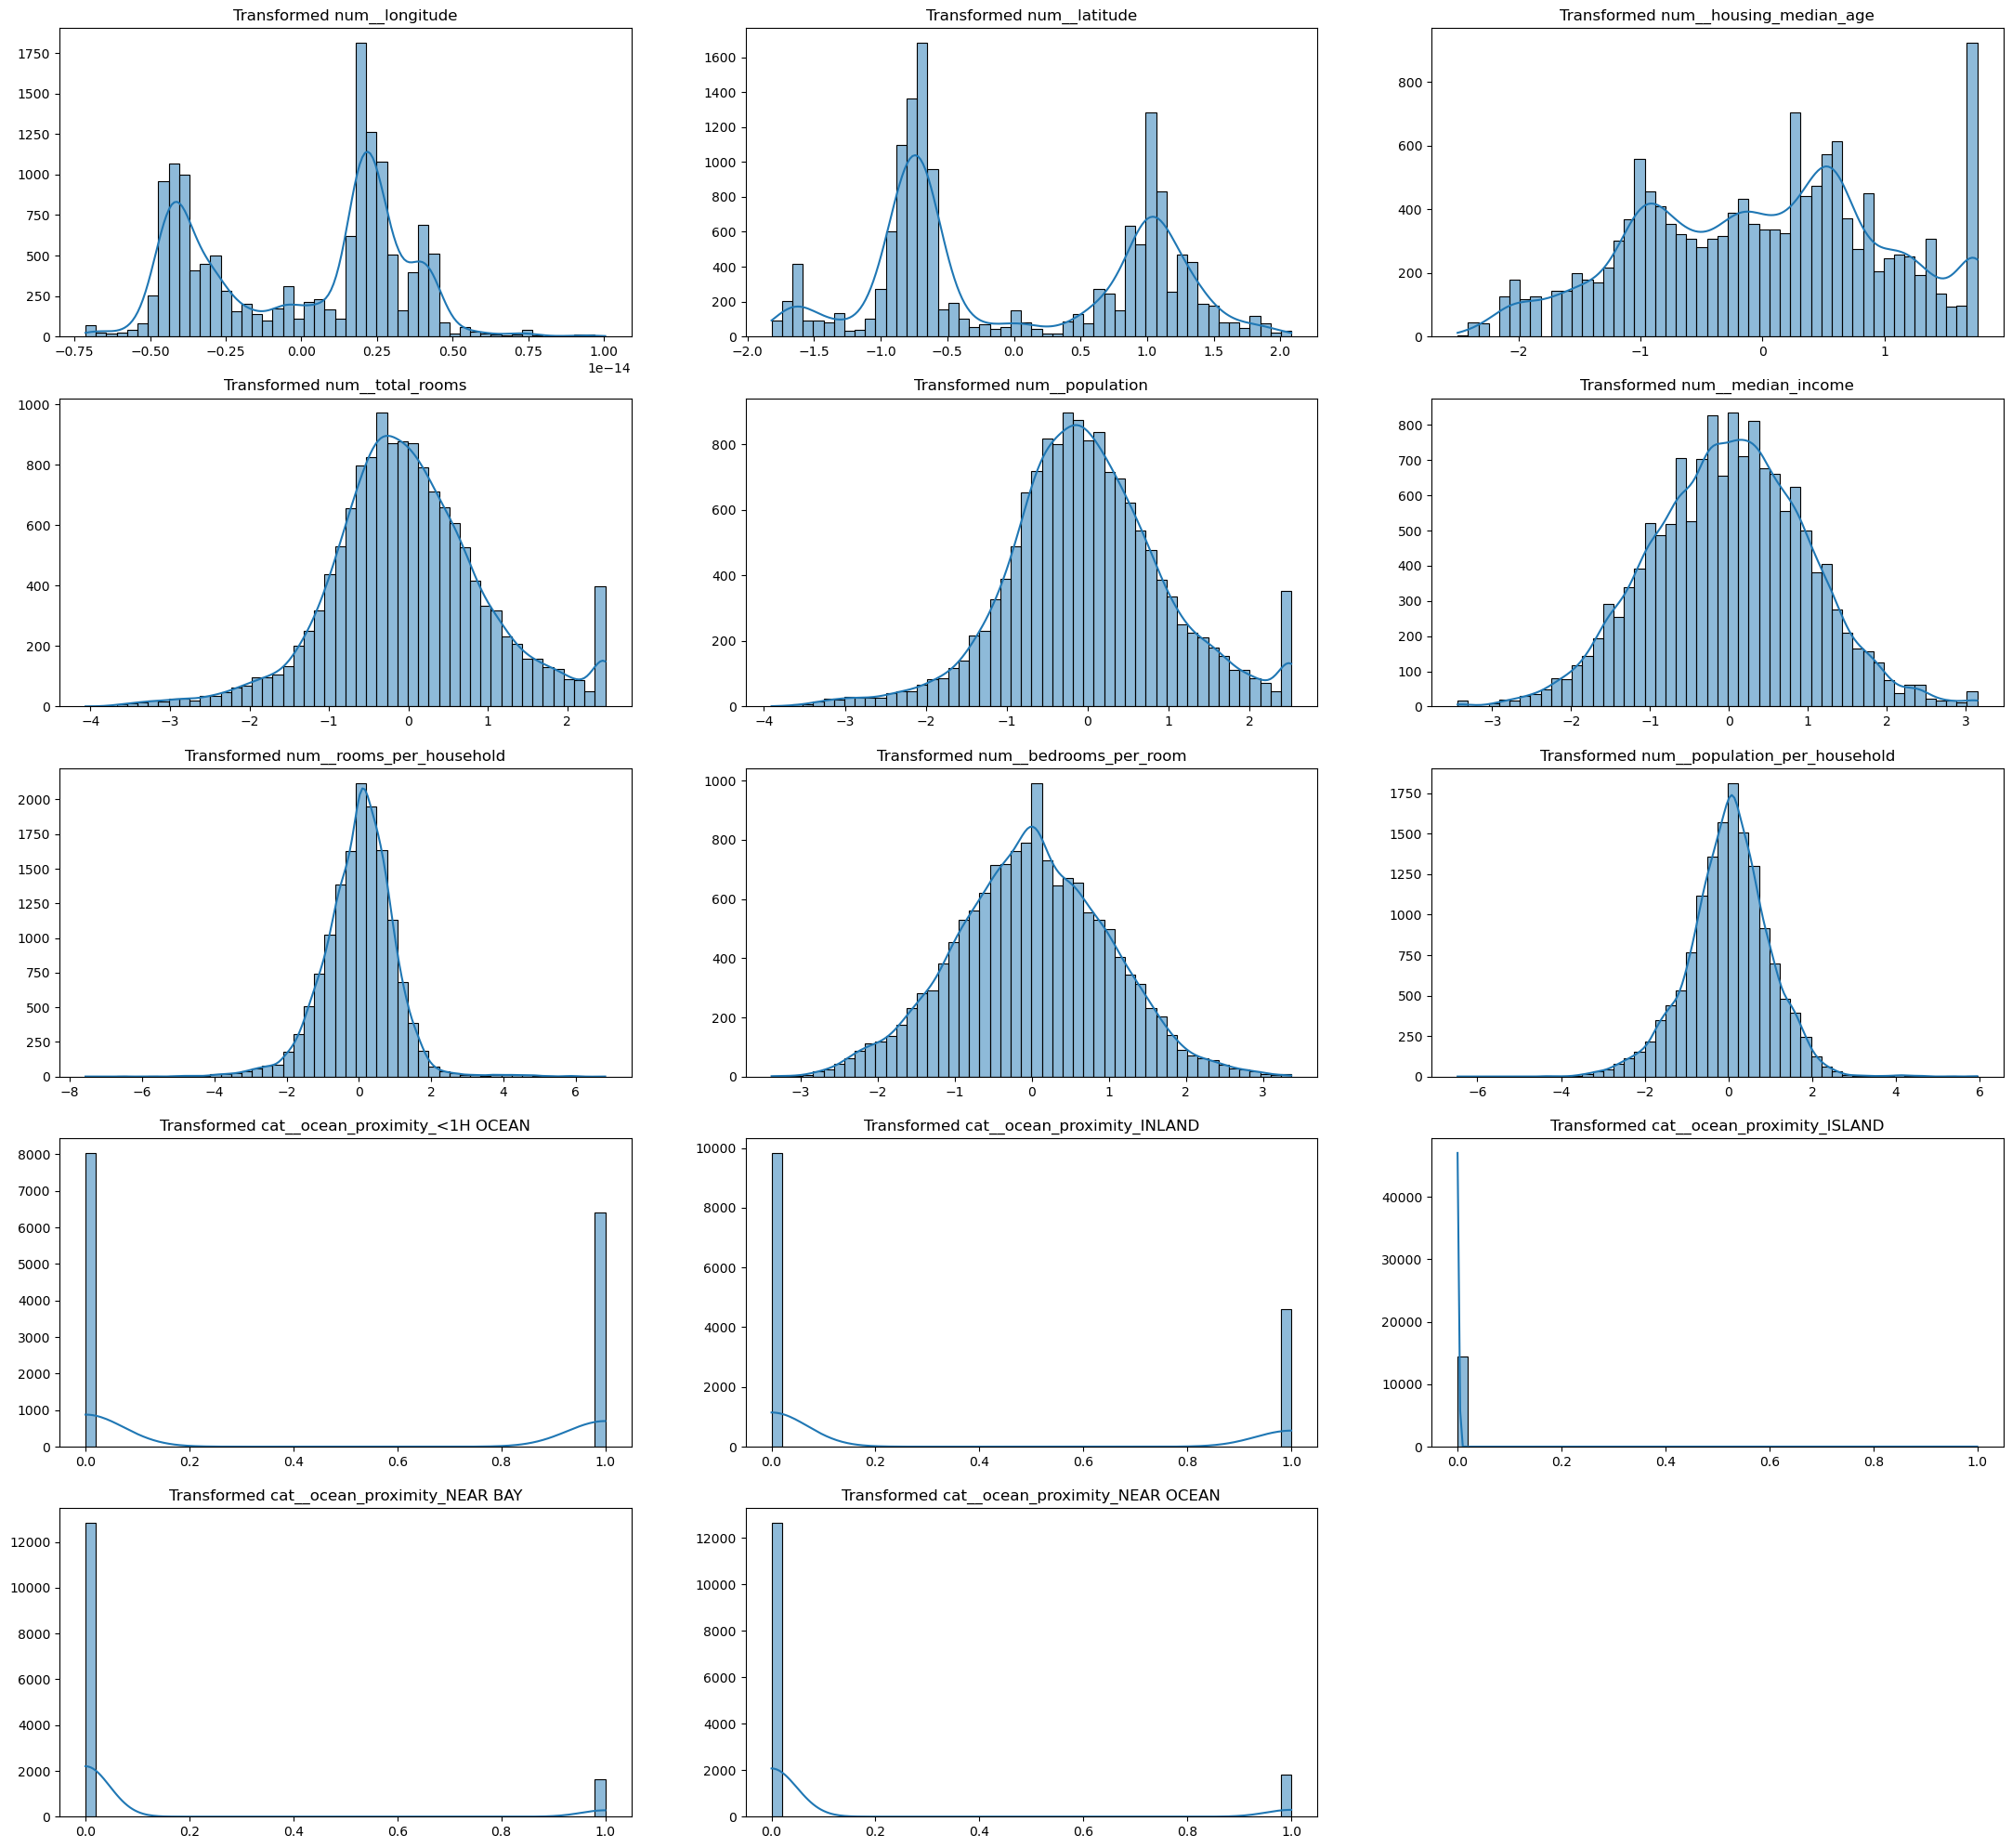

In [137]:
all_graphics(X_train_transformed_df,"Transformed ")

# histograms before transformation

In [122]:
X_train_encoded=preprocessor.fit_transform(X_train)

In [124]:
feature_names=preprocessor.get_feature_names_out()
X_train_encoded_df=pd.DataFrame(data=X_train_encoded,columns=feature_names,index=X_train.index)

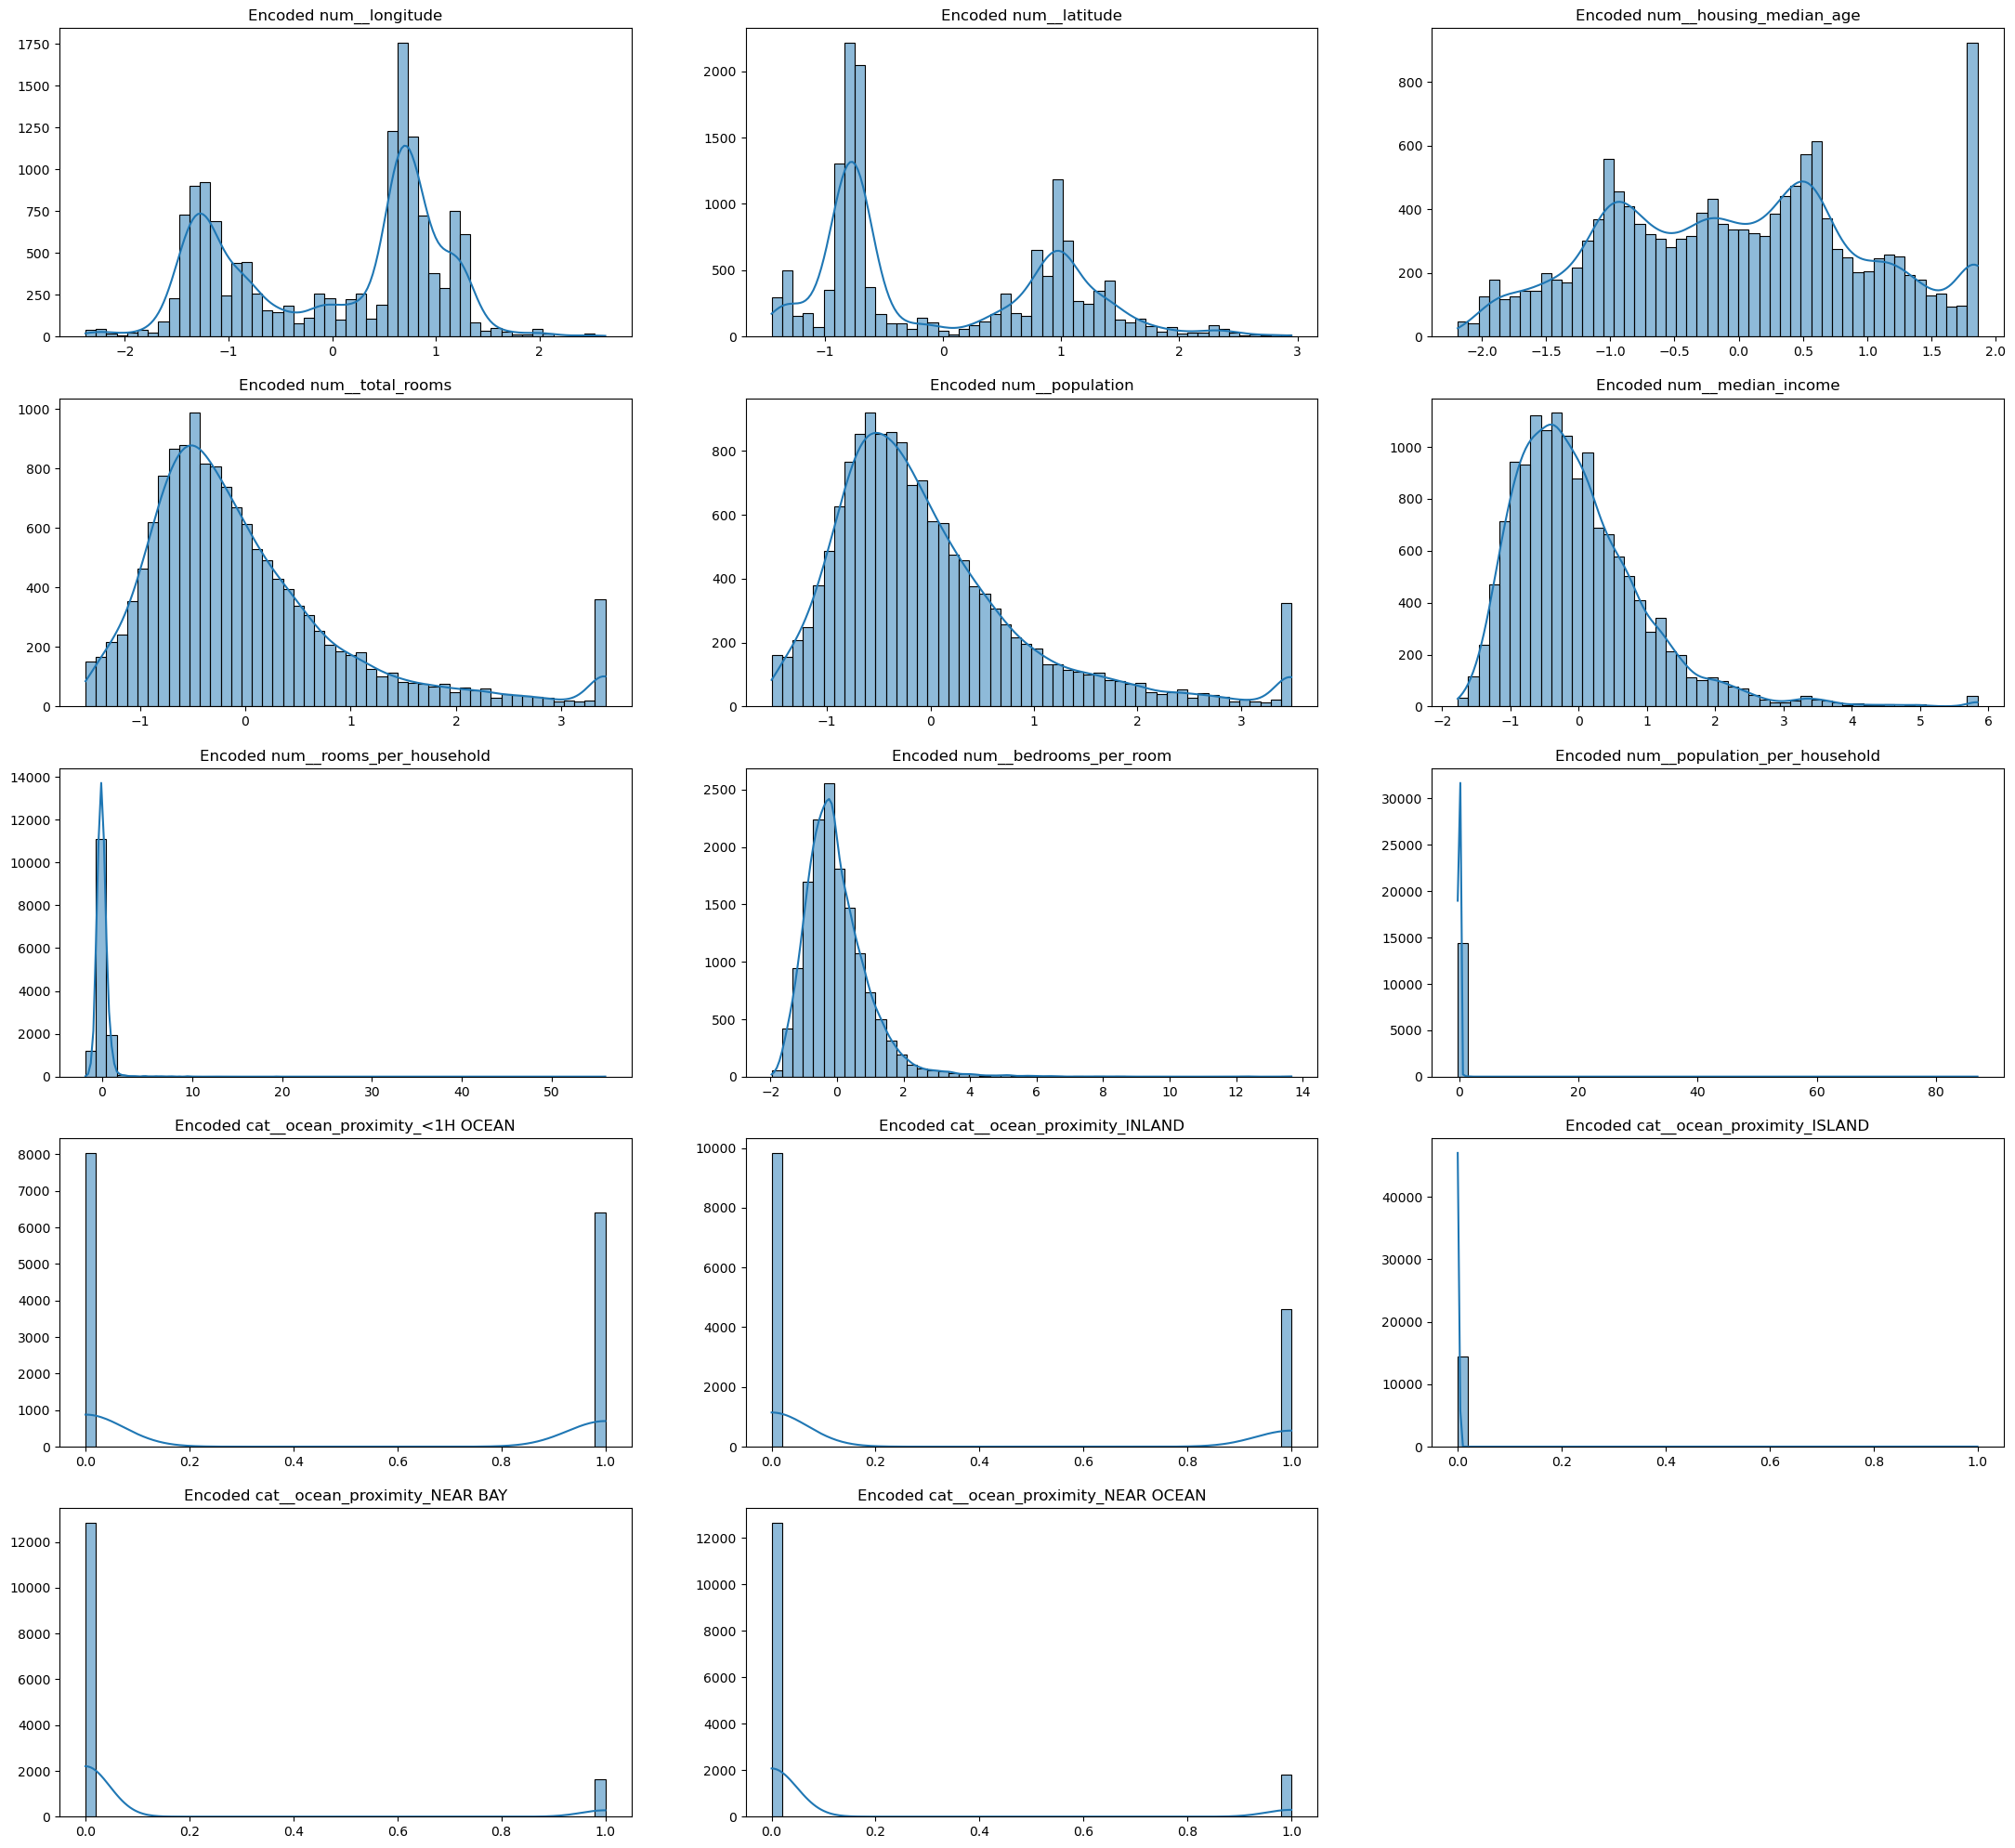

In [125]:
all_graphics(X_train_encoded_df,"Encoded ")

In [126]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('Imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'population', 'median_income', 'rooms_per_household',
       'bedrooms_per_room', 'population_per_household'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['ocean_proximity'])])
